# Tugas - Klasifikasi dengan Support Vector Machine (SVM)

| Nama | NRP |
|------|-----|
| Rasya Gonawi | 5054251032 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model SVM Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja SVM secara praktik, khususnya:
1. Perbedaan hasil antara kernel Linear dan kernel RBF
2. Pengaruh parameter `C` dan `gamma` terhadap gejala overfitting/underfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model SVM dengan kernel Linear dan kernel RBF.
   - Lakukan eksperimen regularisasi dengan variasi nilai `C` dan `gamma`.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [27]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv('data/svm.csv')

print(df.shape)
df.info()



(569, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se    

In [29]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [30]:
df = df.drop(columns=['Unnamed: 32', 'id'])

In [31]:
miss = df.isnull().sum()
print(miss[miss > 0])

Series([], dtype: int64)


In [32]:
df.duplicated().sum().sum()

np.int64(0)

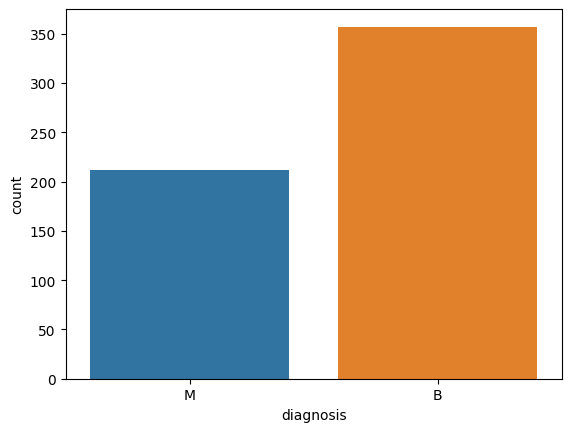

In [33]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

sns.countplot(data = df, hue = 'diagnosis', x = 'diagnosis')
plt.show()

array([[<Axes: title={'center': 'radius_mean'}>,
        <Axes: title={'center': 'texture_mean'}>,
        <Axes: title={'center': 'perimeter_mean'}>,
        <Axes: title={'center': 'area_mean'}>,
        <Axes: title={'center': 'smoothness_mean'}>],
       [<Axes: title={'center': 'compactness_mean'}>,
        <Axes: title={'center': 'concavity_mean'}>,
        <Axes: title={'center': 'concave points_mean'}>,
        <Axes: title={'center': 'symmetry_mean'}>,
        <Axes: title={'center': 'fractal_dimension_mean'}>],
       [<Axes: title={'center': 'radius_se'}>,
        <Axes: title={'center': 'texture_se'}>,
        <Axes: title={'center': 'perimeter_se'}>,
        <Axes: title={'center': 'area_se'}>,
        <Axes: title={'center': 'smoothness_se'}>],
       [<Axes: title={'center': 'compactness_se'}>,
        <Axes: title={'center': 'concavity_se'}>,
        <Axes: title={'center': 'concave points_se'}>,
        <Axes: title={'center': 'symmetry_se'}>,
        <Axes: title={'ce

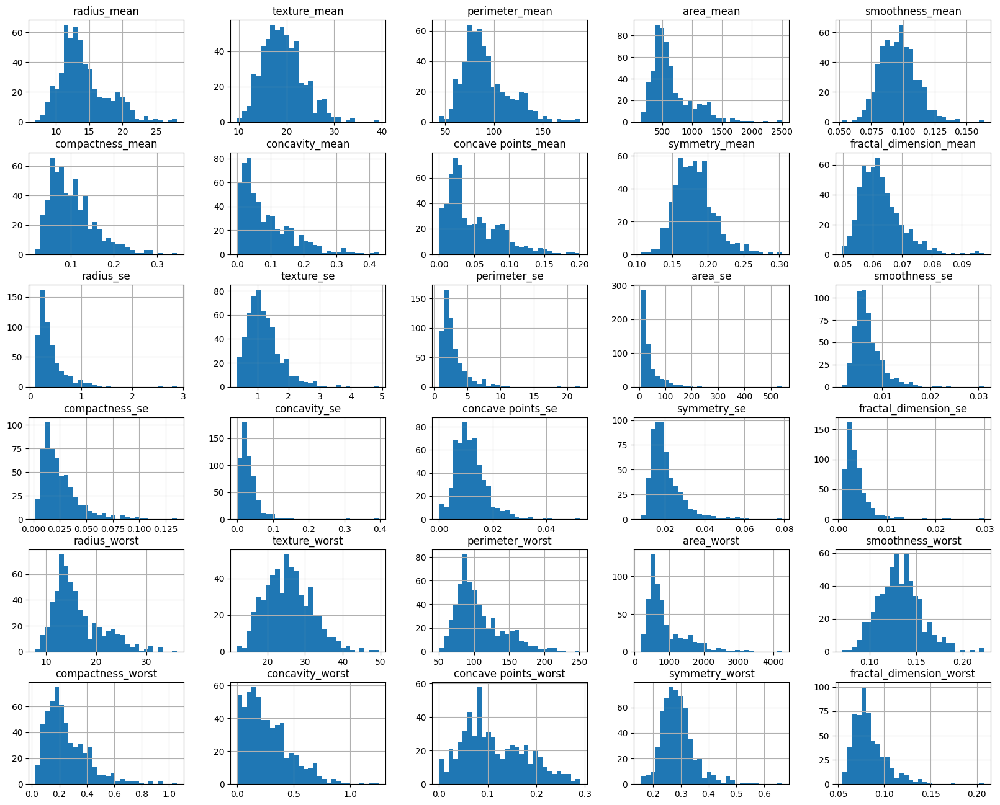

In [34]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau pairplot), dibedakan berdasarkan kelas target.
# Ini membantu melihat apakah ada fitur yang punya batas pemisah yang jelas (linear) antar kelas, atau justru tumpang tindih.

df.hist(bins = 30, figsize=(20,16))

In [35]:
sns.pairplot(df, hue = "diagnosis")

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [36]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.
print(df.isnull().sum()[df.isnull().sum() > 0])


Series([], dtype: int64)


In [37]:
# Jika terdapat fitur kategorikal, lakukan encoding yang sesuai (misalnya One-Hot Encoding atau Ordinal Encoding).

df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})
print(df['diagnosis'].value_counts())


diagnosis
0    357
1    212
Name: count, dtype: int64


In [38]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.

from sklearn.model_selection import train_test_split

X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing :", X_test.shape[0])


Jumlah data training: 455
Jumlah data testing : 114


**Catatan penting:** SVM adalah algoritma berbasis jarak (margin dihitung dari posisi antar titik data), sehingga sangat sensitif terhadap skala fitur. Fitur dengan rentang nilai besar bisa mendominasi perhitungan jarak meskipun sebenarnya tidak lebih penting. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [39]:
# Lakukan feature scaling (StandardScaler) pada fitur numerik.
# fit_transform pada X_train, transform saja pada X_test.

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# 3. Eksperimen Model

## 3.1 SVM dengan Kernel Linear

Kernel Linear mencari hyperplane pemisah berupa garis/bidang lurus, tanpa proyeksi ke dimensi yang lebih tinggi. Cocok digunakan sebagai baseline, terutama jika dari hasil EDA data terlihat cukup terpisah secara linear.

In [40]:
# Inisialisasi dan latih model SVC dengan kernel='linear' menggunakan train set (yang sudah discaling).

from sklearn.svm import SVC

model_linear = SVC(kernel='linear', C=1.0, random_state=42)
model_linear.fit(X_train_scaled, y_train)


,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [41]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.

y_pred_linear = model_linear.predict(X_test_scaled)


## 3.2 SVM dengan Kernel RBF

Kernel RBF (Radial Basis Function) memproyeksikan data ke ruang berdimensi lebih tinggi melalui kernel trick, sehingga mampu menangani batas keputusan yang non-linear.

In [42]:
# Inisialisasi dan latih model SVC dengan kernel='rbf' menggunakan train set.
# Gunakan nilai hyperparameter lain (C) yang sama seperti model Linear di atas, agar perbandingan adil.

model_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
model_rbf.fit(X_train_scaled, y_train)


,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [43]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.

y_pred_rbf = model_rbf.predict(X_test_scaled)


## 3.3 Eksperimen Regularisasi: Pengaruh C dan Gamma terhadap Overfitting

Parameter `C` mengatur trade-off antara margin lebar dan toleransi kesalahan klasifikasi, sedangkan `gamma` (khusus kernel RBF) mengatur seberapa lokal pengaruh tiap titik data. Pada bagian ini kalian akan mengamati bagaimana perubahan nilai `C` (dan/atau `gamma`) memengaruhi akurasi training dan testing.

In [44]:
# Latih beberapa model SVC (kernel RBF) dengan variasi nilai C,
# misalnya 0.01, 0.1, 1, 10, 100.
# Gunakan gamma='scale' atau nilai gamma tetap agar perbandingan fokus pada pengaruh C.

C_values = [0.01, 0.1, 1, 10, 100]
train_accs = []
test_accs = []

for c in C_values:
    clf = SVC(kernel='rbf', C=c, gamma='scale', random_state=42)
    clf.fit(X_train_scaled, y_train)
    train_accs.append(clf.score(X_train_scaled, y_train))
    test_accs.append(clf.score(X_test_scaled, y_test))


In [45]:
# Hitung akurasi pada train set dan test set untuk setiap nilai C yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.

results_C = pd.DataFrame({
    'C': C_values,
    'Train Accuracy': train_accs,
    'Test Accuracy': test_accs
})

results_C


,C,Train Accuracy,Test Accuracy
0,0.01,0.626374,0.631579
1,0.10,0.953846,0.947368
2,1.00,0.986813,0.973684
3,10.00,0.989011,0.973684
4,100.00,1.000000,0.964912


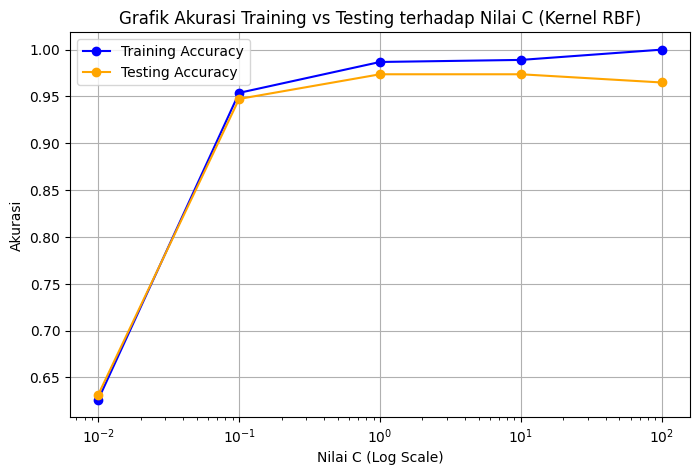

In [46]:
# Plot grafik akurasi training vs testing terhadap nilai C (gunakan sumbu x logaritmik) dalam satu chart.
# Amati pada nilai C berapa model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).

plt.figure(figsize=(8, 5))
plt.plot(C_values, train_accs, marker='o', label='Training Accuracy', color='blue')
plt.plot(C_values, test_accs, marker='o', label='Testing Accuracy', color='orange')
plt.xscale('log')
plt.xlabel('Nilai C (Log Scale)')
plt.ylabel('Akurasi')
plt.title('Grafik Akurasi Training vs Testing terhadap Nilai C (Kernel RBF)')
plt.grid(True)
plt.legend()
plt.show()


# 4. Evaluasi Model

In [47]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model kernel Linear dan RBF.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

metrics_summary = pd.DataFrame({
    'Kernel': ['Linear', 'RBF'],
    'Accuracy': [accuracy_score(y_test, y_pred_linear), accuracy_score(y_test, y_pred_rbf)],
    'Precision': [precision_score(y_test, y_pred_linear), precision_score(y_test, y_pred_rbf)],
    'Recall': [recall_score(y_test, y_pred_linear), recall_score(y_test, y_pred_rbf)],
    'F1-Score': [f1_score(y_test, y_pred_linear), f1_score(y_test, y_pred_rbf)]
})

metrics_summary


,Kernel,Accuracy,Precision,Recall,F1-Score
0,Linear,0.964912,1.0,0.904762,0.950000
1,RBF,0.973684,1.0,0.928571,0.962963


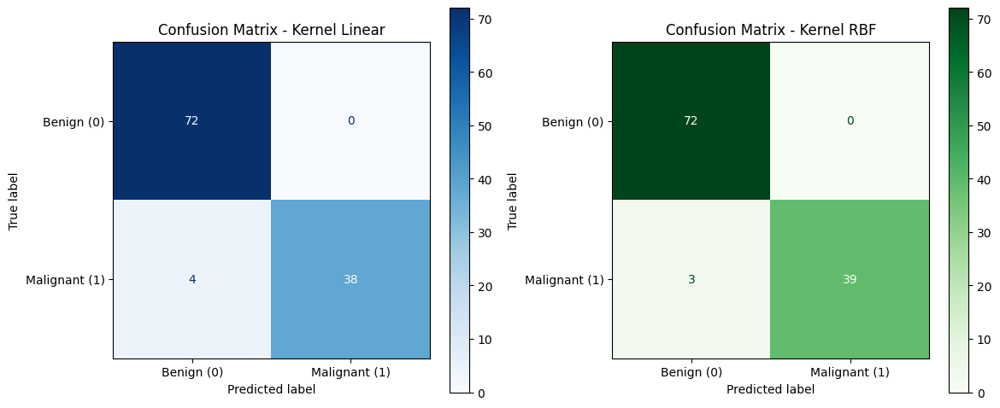

In [48]:
# Tampilkan Confusion Matrix untuk model kernel Linear dan RBF dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_linear = confusion_matrix(y_test, y_pred_linear)
disp_linear = ConfusionMatrixDisplay(cm_linear, display_labels=['Benign (0)', 'Malignant (1)'])
disp_linear.plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Confusion Matrix - Kernel Linear')

cm_rbf = confusion_matrix(y_test, y_pred_rbf)
disp_rbf = ConfusionMatrixDisplay(cm_rbf, display_labels=['Benign (0)', 'Malignant (1)'])
disp_rbf.plot(ax=axes[1], cmap='Greens')
axes[1].set_title('Confusion Matrix - Kernel RBF')

plt.tight_layout()
plt.show()


In [49]:
# Tampilkan jumlah support vectors dari model dengan performa terbaik (atribut model.support_vectors_ atau model.n_support_).
# Bandingkan jumlah support vectors antara model Linear dan RBF.

print("Jumlah Support Vectors Kernel Linear:", model_linear.n_support_.sum(), f"(Benign: {model_linear.n_support_[0]}, Malignant: {model_linear.n_support_[1]})")
print("Jumlah Support Vectors Kernel RBF   :", model_rbf.n_support_.sum(), f"(Benign: {model_rbf.n_support_[0]}, Malignant: {model_rbf.n_support_[1]})")


Jumlah Support Vectors Kernel Linear: 38 (Benign: 19, Malignant: 19)
Jumlah Support Vectors Kernel RBF   : 107 (Benign: 50, Malignant: 57)


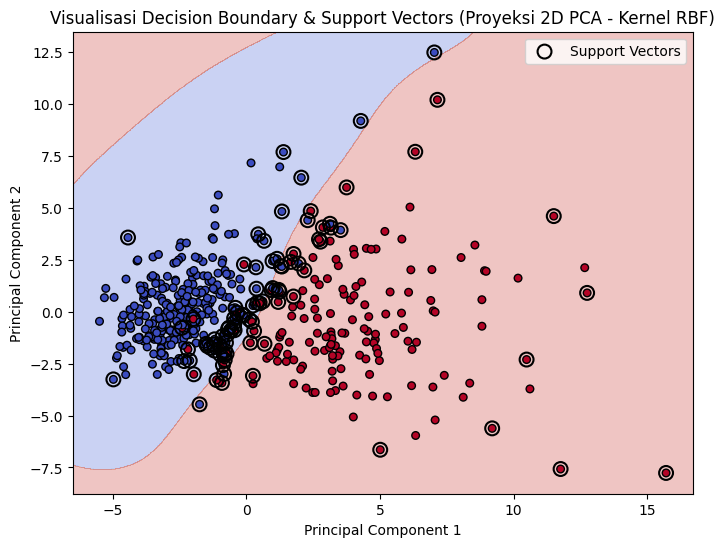

In [50]:
# Jika memungkinkan, pilih dua fitur (atau reduksi dimensi dengan PCA ke 2D) lalu visualisasikan decision boundary
# beserta margin dan support vectors dari model terbaik.

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)

clf_pca = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
clf_pca.fit(X_train_pca, y_train)

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

Z = clf_pca.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', s=30)
plt.scatter(clf_pca.support_vectors_[:, 0], clf_pca.support_vectors_[:, 1], s=100, facecolors='none', edgecolors='k', linewidths=1.5, label='Support Vectors')

plt.title('Visualisasi Decision Boundary & Support Vectors (Proyeksi 2D PCA - Kernel RBF)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()


# 5. Analisis

Hasil Analisis Eksperimen SVM:

1. Perbandingan Kernel Linear vs Kernel RBF:
- Pada dataset Breast Cancer ini, kedua kernel memberikan performa akurasi yang sangat tinggi. Kernel Linear mencapai akurasi 96,49% (F1-score 95,00%), sedangkan Kernel RBF mencapai akurasi 97,37% (F1-score 96,30%).
- Performa Kernel RBF sedikit lebih unggul dibanding Kernel Linear. Berdasarkan eksplorasi awal (EDA), hal ini dikarenakan sebaran fitur-fitur kanker payudara umumnya dapat dipisahkan secara linier dengan baik, namun sebagian kecil fitur memiliki area tumpang tindih  di batas antar kelas yang membutuhkan pemisah non-linier seperti kernel RBF untuk mencapai pemisahan yang lebih presisi.

2. Pengaruh Hyperparameter Regularisasi (Nilai C):
- Nilai C kecil (C = 0.01): Model mengalami underfitting berat, di mana akurasi training dan testing hanya berada di kisaran 62%-63%. Margin yang terbentuk terlalu lebar sehingga toleransi kesalahan terlalu tinggi.
- Nilai C sedang (C = 0.1 hingga C = 1.0): Performa model meningkat pesat dan mencapai titik optimal pada C = 1.0 dengan akurasi testing 97,37% dan akurasi training 98,68%.
- Nilai C sangat tinggi (C = 100): Akurasi training mencapai 100%, tetapi akurasi testing turun dari 97,37% menjadi 96,49%. Ciri-ciri overfitting mulai terlihat dari grafik, di mana akurasi training terus naik sampai sempurna sementara akurasi testing stagnan lalu mulai menurun.

3. Perbandingan Jumlah Support Vector:
- Kernel Linear hanya membutuhkan 38 support vectors (sekitar 8,3% dari total data training) untuk membentuk hyperplane pemisah linier.
- Kernel RBF membutuhkan 107 support vectors (sekitar 23,5% dari total data training).
- Hubungan jumlah support vectors dengan kompleksitas batas keputusan: Kernel RBF membentuk batas keputusan yang lebih kompleks dan fleksibel mengelilingi titik data di area transisi, sehingga memerlukan lebih banyak titik support vectors dibandingkan kernel Linear yang hanya membentuk garis/bidang lurus sederhana


# 6. Kesimpulan dan Saran

Berikan kesimpulan dari eksperimen yang telah dilakukan:

1. Kesimpulan:
- Algoritma Support Vector Machine sangat efektif untuk mengklasifikasikan diagnosis kanker payudara (Benign vs Malignant) dengan akurasi di atas 96%.
- Feature scaling menggunakan StandardScaler terbukti sangat krusial agar seluruh fitur numerik berkontribusi seimbang dalam perhitungan jarak margin SVM
- Model dengan Kernel RBF pada parameter C = 1.0 dan gamma = 'scale' memberikan performa terbaik pada test set dengan akurasi 97,37%, precision 100%, recall 92,86%, dan F1-score 96,30%.
- Pemilihan nilai C yang terlalu besar (C = 100) dapat memicu overfitting karena margin pemisah menjadi terlalu sempit dan sangat sensitif terhadap outlier.

2. Saran:
- Melakukan hyperparameter tuning lebih lanjut secara otomatis menggunakan GridSearchCV untuk mencari kombinasi optimal nilai C dan gamma secara bersamaan.
- Mencoba kernel lain seperti Kernel Polynomial atau Sigmoid untuk membandingkan karakteristik fleksibilitas batas keputusannya.
- Menggunakan teknik reduksi dimensi seperti PCA sebelum pelatihan model untuk mengurangi beban komputasi fitur yang saling berkorelasi tinggi.
